# 02 · Feature analysis

Three handcrafted descriptor families and why they are fused. Features are read from the cache in `data/features/` (run `scripts/run_feature_extraction.py` first).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data_loader, preprocess
from src.utils import setup_matplotlib
plt = setup_matplotlib()
%matplotlib inline
MET, FIG = config.PATHS.metrics, config.PATHS.figures
def show(name):
    from IPython.display import Image, display
    p = FIG / name
    display(Image(filename=str(p))) if p.exists() else print(f"{name} not generated yet")
from src.features import fusion, hog_features, zernike_features, lbp_features

In [2]:
summary = json.loads((MET / 'feature_summary.json').read_text())
pd.DataFrame(summary['families'])[['family', 'n_features', 'ms_per_image', 'constant_features']]

,family,n_features,ms_per_image,constant_features
0,hog,1764,0.470,0
1,zernike,49,0.358,0
2,lbp,448,0.585,0


## What each descriptor sees

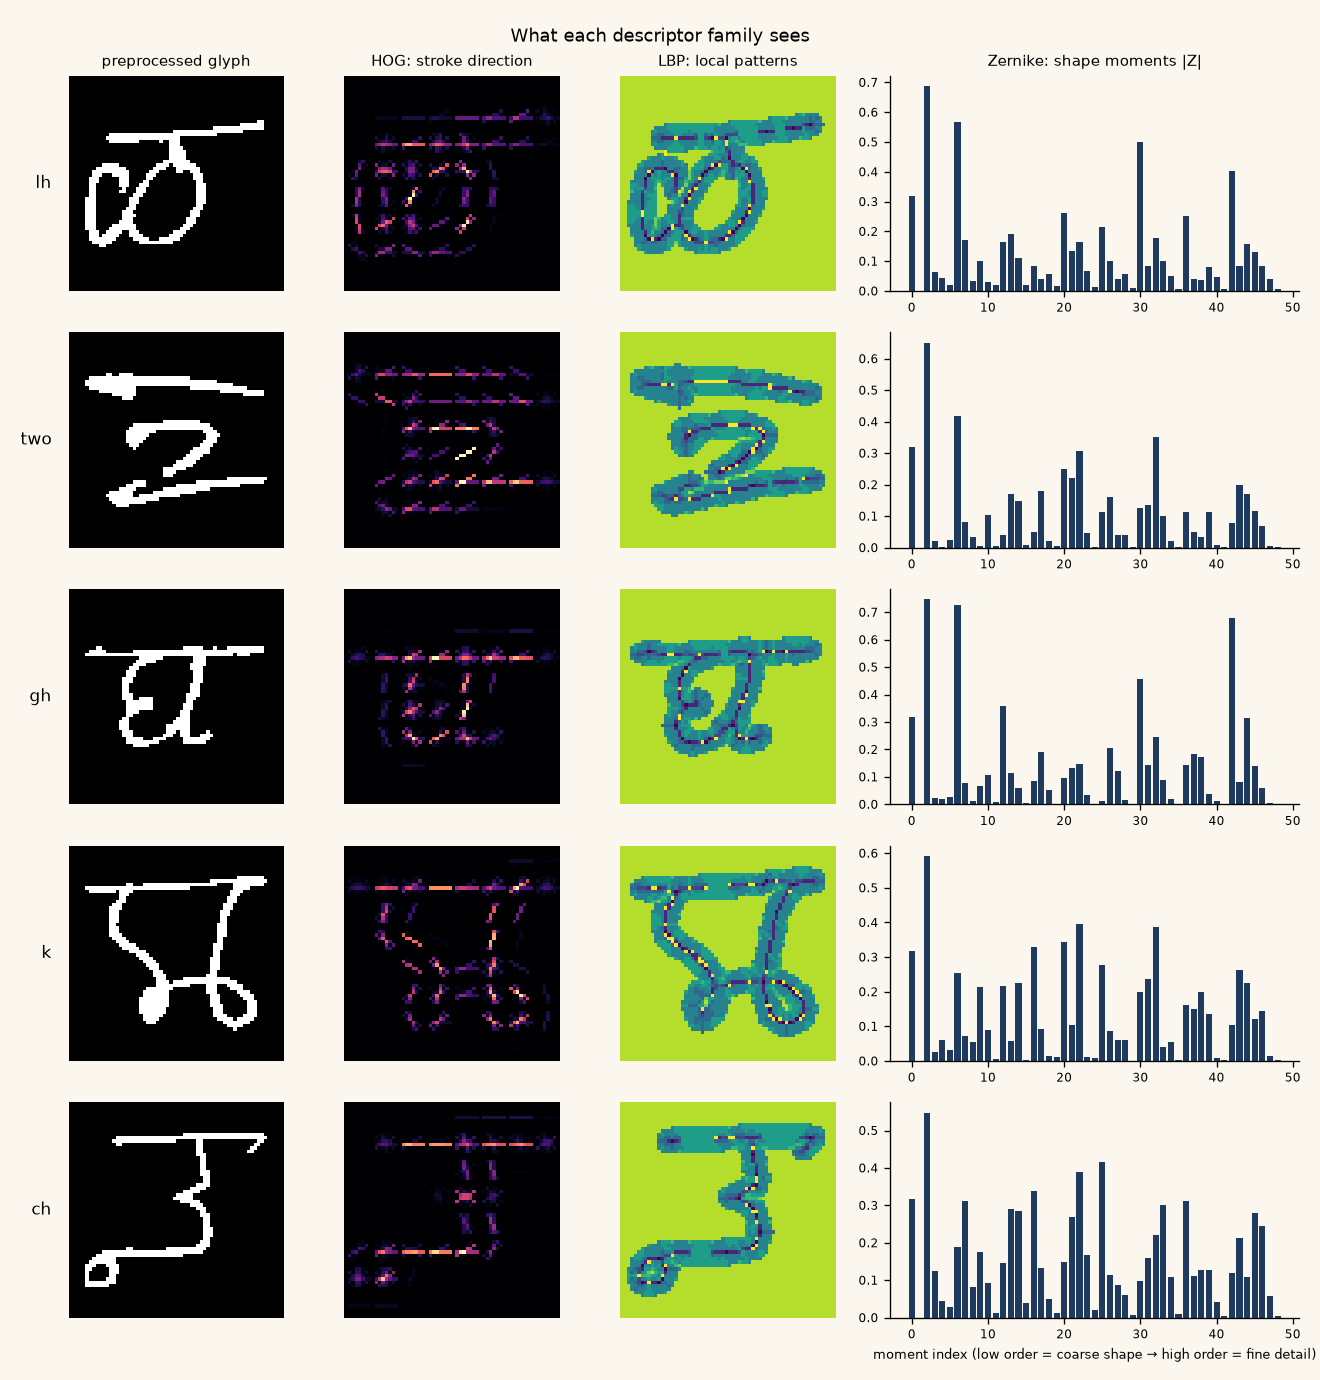

In [3]:
show('feature_examples.png')

## Complementarity: rotation
Zernike magnitudes are rotation invariant; HOG is not. This is measured on real glyphs, not assumed.

In [4]:
import cv2
index = data_loader.load_processed_index()
imgs = data_loader.load_processed_images(index)
rng = np.random.default_rng(42); pick = rng.choice(len(imgs), 200, replace=False)
rows = []
for ang in (2, 5, 10, 20):
    for m, mod in (('HOG', hog_features), ('Zernike', zernike_features), ('LBP', lbp_features)):
        d = []
        for i in pick[:60]:
            im = imgs[i]; M = cv2.getRotationMatrix2D((32, 32), ang, 1.0)
            r = cv2.warpAffine(im, M, (64, 64), flags=cv2.INTER_NEAREST)
            a, b = mod.extract(im), mod.extract(r); d.append(np.linalg.norm(a - b) / (np.linalg.norm(a) + 1e-9))
        rows.append({'angle': ang, 'descriptor': m, 'relative change': np.mean(d)})
pd.DataFrame(rows).pivot(index='angle', columns='descriptor', values='relative change').round(3)

descriptor,HOG,LBP,Zernike
angle,,,
2,0.356,0.055,0.029
5,0.529,0.096,0.022
10,0.736,0.170,0.024
20,1.010,0.246,0.034


## How separable is each family on its own?
Fisher-style ratio of between-class to within-class variance per feature (higher = more discriminative), on the main training split.

In [5]:
idx = index.assign(_pos=np.arange(len(index)))
train, _, _ = data_loader.stratified_split(idx, 500, quiet=True)
X = fusion.load_feature_set(index, 'fused')[train['_pos'].to_numpy()]
y = train['label'].to_numpy()
mu = X.mean(0); classes = np.unique(y)
between = sum((y == c).sum() * (X[y == c].mean(0) - mu) ** 2 for c in classes)
within = sum(((X[y == c] - X[y == c].mean(0)) ** 2).sum(0) for c in classes)
fisher = between / (within + 1e-9)
{f: float(np.median(fisher[s])) for f, s in fusion.slices().items()}

{'hog': 0.14830074179660246,
 'zernike': 0.2086822645836134,
 'lbp': 0.17988021641182206}

## Family-balanced fusion
After standardising, each family gets weight 1/√n so the three contribute equal total variance. Without it HOG is 78% of the vector.

In [6]:
sl = fusion.slices(); n = {k: s.stop - s.start for k, s in sl.items()}
print('share of dimensions:', {k: f'{100 * v / sum(n.values()):.1f}%' for k, v in n.items()})
w = fusion.FamilyBalancer().fit(np.zeros((2, sum(n.values())))).weights_
print('share of variance after balancing:', {k: f'{100 * (w[s] ** 2).sum() / (w ** 2).sum():.1f}%' for k, s in sl.items()})

share of dimensions: {'hog': '78.0%', 'zernike': '2.2%', 'lbp': '19.8%'}
share of variance after balancing: {'hog': '33.3%', 'zernike': '33.3%', 'lbp': '33.3%'}


## Reduced space

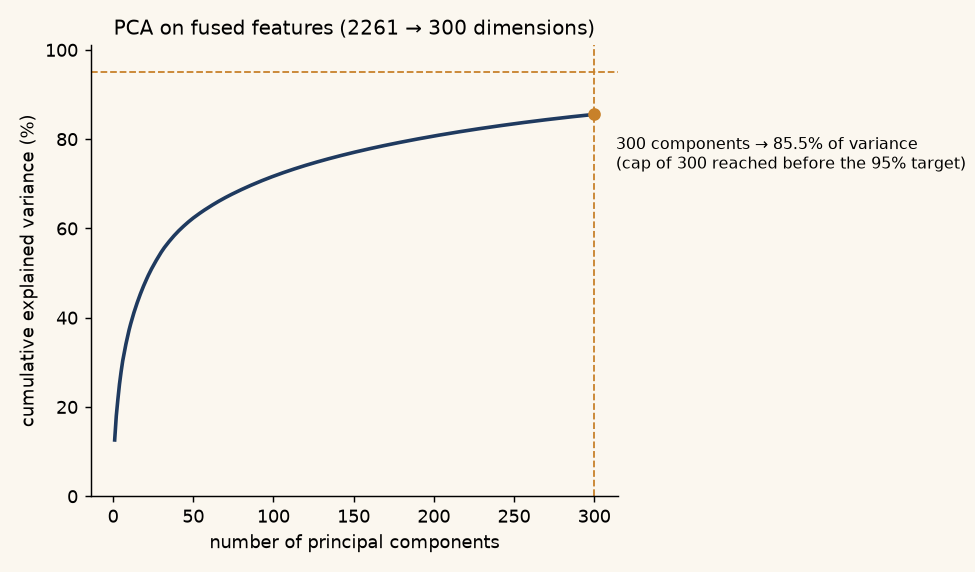

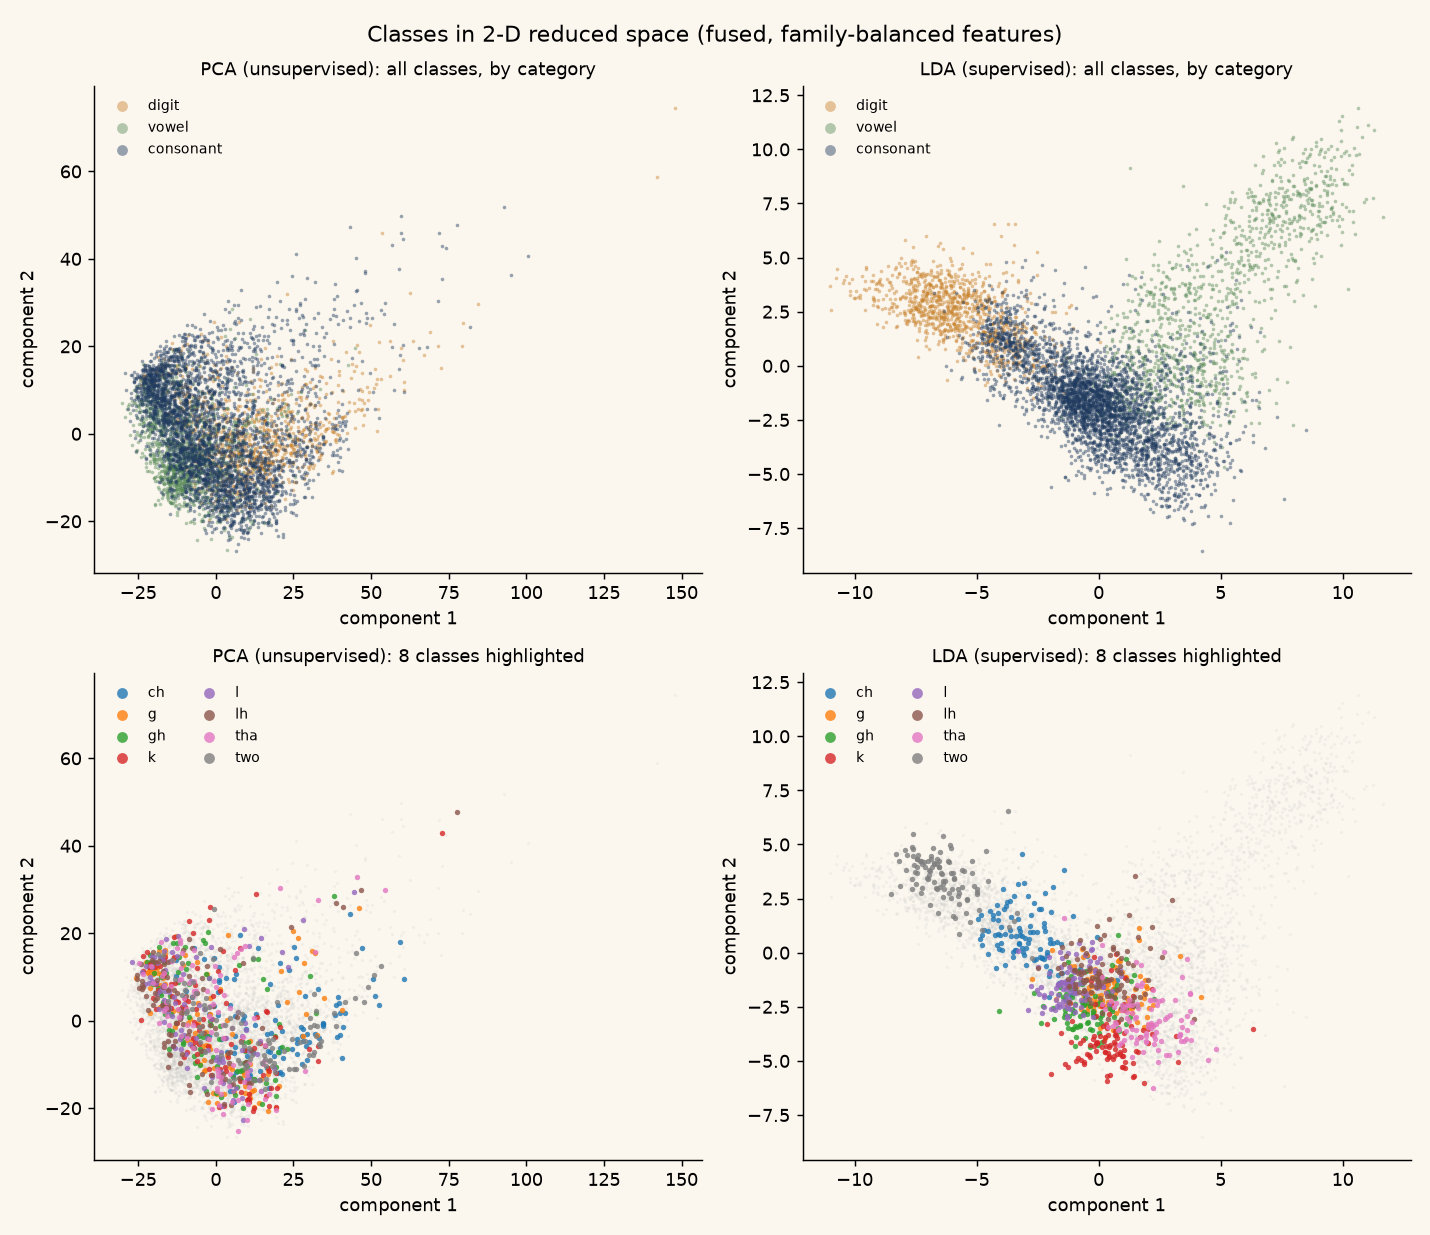

In [7]:
show('pca_explained_variance.png'); show('reduction_scatter_2d.png')